# Compare SOC outputs: `09_emissions_soc.py` (new) vs `old_soc.py` (legacy)

This notebook runs **both** SOC scripts, captures their in-memory results, and compares:

1. **Input-level assignment** — how many farms fall in each `fi_level`
   (Low / Medium / High_no_manure / High_with_manure), and how they moved.
2. **`soc_delta_t_co2eq`** — the SOC-change emissions, with a **driver decomposition**
   attributing the old→new change to each factor: SOCref, FLU, FMG (tillage),
   FI (input level), and the BAU baseline.

**The two scripts differ in five places**, all of which move `soc_delta`:

| Factor | `old_soc.py` | `09_emissions_soc.py` (new) |
|---|---|---|
| SOCref | GSOCseq value | IPCC 2019 Table 2.3 (climate × soil) |
| FLU | 2006 values | 2019 values |
| FMG (tillage) | 2006 values | 2019 values |
| FI classification | legacy thresholds (residues ≥80/40, compost = manure) | IPCC Fig 5.1 node traversal (60%, 8 t/ha, mineral-N gate) |
| FI_MAPPING coverage | Warm Temperate missing → `None` | Warm Temperate filled |

> ⚠️ **Side effect:** running this notebook executes the full pipeline for each script, which
> **overwrites** `table_09_emissions_soc` (feather + SQL). The scripts run *old first, then new
> last*, so the on-disk table ends in the **new** state.

In [116]:
%matplotlib inline
import os
import sys
import runpy
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

pd.set_option("display.max_columns", 100)

# --- Repo layout (edit REPO_ROOT if you move the notebook) -------------------
REPO_ROOT = Path("/Users/giorgioparlato/githu_cimmyt/esi_cimmyt")
SCRIPTS_DIR = REPO_ROOT / "code" / "esi_computation" / "scripts"
NEW_SCRIPT = SCRIPTS_DIR / "09_emissions_soc.py"
OLD_SCRIPT = REPO_ROOT / "code" / "esi_computation" / "scripts" / "old_soc.py"

for p in (SCRIPTS_DIR, NEW_SCRIPT, OLD_SCRIPT):
    assert p.exists(), f"Not found: {p}"

LEVEL_ORDER = ["Low", "Medium", "High_no_manure", "High_with_manure"]
KEYS = ["farmer_id", "plot_id", "logbook_id", "practice_id", "year"]
print("Scripts located OK.")

Scripts located OK.


In [117]:
def run_script(path):
    """Execute a pipeline script via runpy (scripts/ on sys.path and as cwd) and return its
    final global namespace. NOTE: this triggers the script's feather/SQL writes."""
    path = Path(path)
    prev_cwd = Path.cwd()
    added = str(SCRIPTS_DIR) not in sys.path
    if added:
        sys.path.insert(0, str(SCRIPTS_DIR))
    try:
        os.chdir(SCRIPTS_DIR)
        ns = runpy.run_path(str(path), run_name="__main__")
    finally:
        os.chdir(prev_cwd)
        if added and str(SCRIPTS_DIR) in sys.path:
            sys.path.remove(str(SCRIPTS_DIR))
    return ns

# Run OLD first, then NEW last (so table_09 on disk ends as the new version)
print("Running old_soc.py ...")
old_ns = run_script(OLD_SCRIPT)
print("Running 09_emissions_soc.py ...")
new_ns = run_script(NEW_SCRIPT)

old = old_ns["soc_df_estimation"].copy()
new = new_ns["soc_df_estimation"].copy()
print("old soc_df_estimation:", old.shape)
print("new soc_df_estimation:", new.shape)


Running old_soc.py ...


/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/openpyxl/packaging/core.py:99: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  now = datetime.datetime.utcnow()
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/openpyxl/packaging/core.py:99: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  now = datetime.datetime.utcnow()


Execution complete.
Running 09_emissions_soc.py ...


/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/openpyxl/packaging/core.py:99: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  now = datetime.datetime.utcnow()
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/openpyxl/packaging/core.py:99: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  now = datetime.datetime.utcnow()


Execution complete.
old soc_df_estimation: (68694, 27)
new soc_df_estimation: (68694, 35)


In [118]:
FACTOR_COLS = [
    "climate_class", "soc_ref", "flu", "ftill", "fi", "fi_bau", "fi_level", "ca_fao_dummy",
    "area_ha", "soc_0", "soc_1", "soc_delta", "soc_delta_t_co2eq", "soc_delta_t_co2eq_ha",
]

# Duplicate-key check (grain should be one row per farmer/plot/logbook/practice/year)
for name, df in [("old", old), ("new", new)]:
    print(f"{name}: {df.duplicated(KEYS).sum()} duplicate key rows")

old_sel = old[KEYS + FACTOR_COLS]
new_sel = new[KEYS + FACTOR_COLS]
cmp = old_sel.merge(new_sel, on=KEYS, how="outer", suffixes=("_old", "_new"), indicator=True)
print("\nMerge overlap:")
print(cmp["_merge"].value_counts())

# Coerce factor columns to numeric (legacy fi/fi_bau can be None for Warm Temperate)
NUM_COLS = ["soc_ref", "flu", "ftill", "fi", "fi_bau", "area_ha",
            "soc_0", "soc_1", "soc_delta", "soc_delta_t_co2eq", "soc_delta_t_co2eq_ha"]
for cc in NUM_COLS:
    for suf in ("_old", "_new"):
        cmp[cc + suf] = pd.to_numeric(cmp[cc + suf], errors="coerce")

both = cmp[cmp["_merge"] == "both"].copy()
print(f"\nMatched rows: {len(both)}")
print("soc_delta_t_co2eq null — old:", both["soc_delta_t_co2eq_old"].isna().sum(),
      "| new:", both["soc_delta_t_co2eq_new"].isna().sum())

old: 0 duplicate key rows
new: 0 duplicate key rows

Merge overlap:
_merge
both          68694
left_only         0
right_only        0
Name: count, dtype: int64

Matched rows: 68694
soc_delta_t_co2eq null — old: 220 | new: 362


## 1. Input-level (`fi_level`) assignment

How many farms land in each carbon-input level under each script, and how they moved.

,old,new,change,pct_old,pct_new
fi_level,,,,,
Low,43725,46124,2399,63.7,67.1
Medium,8216,21604,13388,12.0,31.4
High_no_manure,16370,604,-15766,23.8,0.9
High_with_manure,383,362,-21,0.6,0.5


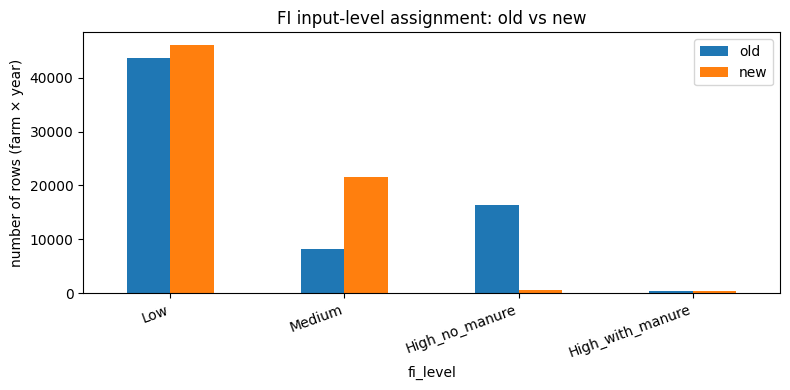

In [119]:
def level_counts(df):
    extra = [x for x in df["fi_level"].dropna().unique() if x not in LEVEL_ORDER]
    return df["fi_level"].value_counts(dropna=False).reindex(LEVEL_ORDER + extra)

lvl = pd.concat([level_counts(old), level_counts(new)], axis=1, keys=["old", "new"])
lvl = lvl.fillna(0).astype(int)
lvl["change"] = lvl["new"] - lvl["old"]
lvl["pct_old"] = (100 * lvl["old"] / lvl["old"].sum()).round(1)
lvl["pct_new"] = (100 * lvl["new"] / lvl["new"].sum()).round(1)
display(lvl)

ax = lvl[["old", "new"]].plot(kind="bar", figsize=(8, 4))
ax.set_ylabel("number of rows (farm × year)")
ax.set_title("FI input-level assignment: old vs new")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

Transition matrix (rows = old level, cols = new level):


new,Low,Medium,High_no_manure,High_with_manure
old,,,,
Low,41887,1838,0,0
Medium,4237,3396,493,90
High_no_manure,0,16370,0,0
High_with_manure,0,0,111,272


Rows that changed level: 23139 / 68694 (33.7%)


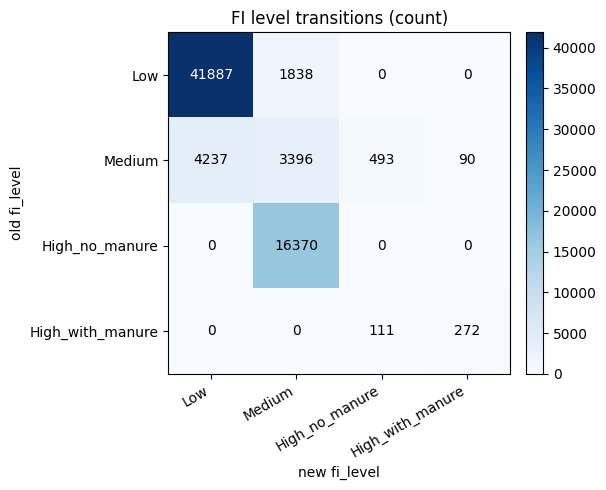

In [120]:
trans = pd.crosstab(both["fi_level_old"], both["fi_level_new"],
                    rownames=["old"], colnames=["new"], dropna=False)
order_r = [l for l in LEVEL_ORDER if l in trans.index] + [l for l in trans.index if l not in LEVEL_ORDER]
order_c = [l for l in LEVEL_ORDER if l in trans.columns] + [l for l in trans.columns if l not in LEVEL_ORDER]
trans = trans.reindex(index=order_r, columns=order_c).fillna(0).astype(int)
print("Transition matrix (rows = old level, cols = new level):")
display(trans)

n_changed = int((both["fi_level_old"] != both["fi_level_new"]).sum())
print(f"Rows that changed level: {n_changed} / {len(both)} ({100*n_changed/len(both):.1f}%)")

fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(trans.values, cmap="Blues")
ax.set_xticks(range(len(trans.columns))); ax.set_xticklabels(trans.columns, rotation=30, ha="right")
ax.set_yticks(range(len(trans.index))); ax.set_yticklabels(trans.index)
ax.set_xlabel("new fi_level"); ax.set_ylabel("old fi_level")
ax.set_title("FI level transitions (count)")
vmax = trans.values.max()
for i in range(trans.shape[0]):
    for j in range(trans.shape[1]):
        v = trans.values[i, j]
        ax.text(j, i, v, ha="center", va="center", color="white" if v > vmax / 2 else "black")
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout(); plt.show()

## 2. `soc_delta_t_co2eq` comparison

Totals and distributions of the SOC-change emissions (negative = sequestration).

,old,new
count,68474.000,68332.000
mean,-0.929,-0.190
std,2.862,0.354
min,-152.522,-10.344
25%,-0.763,-0.224
50%,-0.107,-0.000
75%,-0.000,0.000
max,-0.000,0.111
sum,-20876.818,-12965.181


Mean soc_delta_t_co2eq_ha — old: -0.3049 | new: -0.1897 t CO2eq/ha


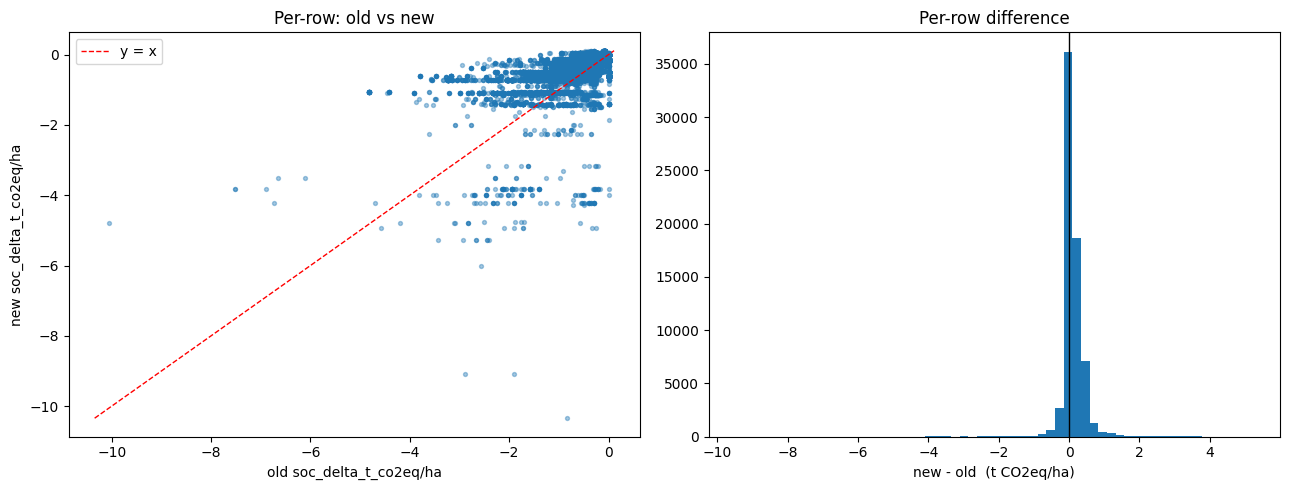

Mean per-row change (new-old): 0.1146 t CO2eq/ha; median: 0.0000


In [134]:
m = both.dropna(subset=["soc_delta_t_co2eq_ha_old", "soc_delta_t_co2eq_ha_new"]).copy()

summary = pd.DataFrame({
    "old": both["soc_delta_t_co2eq_old"].describe(),
    "new": both["soc_delta_t_co2eq_ha_new"].describe(),
})
summary.loc["sum"] = [both["soc_delta_t_co2eq_ha_old"].sum(), both["soc_delta_t_co2eq_ha_new"].sum()]
display(summary.round(3))

print(f"Mean soc_delta_t_co2eq_ha — old: {both['soc_delta_t_co2eq_ha_old'].mean():.4f}"
      f" | new: {both['soc_delta_t_co2eq_ha_new'].mean():.4f} t CO2eq/ha")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].scatter(m["soc_delta_t_co2eq_ha_old"], m["soc_delta_t_co2eq_ha_new"], s=8, alpha=0.4)
lim = [min(m["soc_delta_t_co2eq_ha_old"].min(), m["soc_delta_t_co2eq_ha_new"].min()),
       max(m["soc_delta_t_co2eq_ha_old"].max(), m["soc_delta_t_co2eq_ha_new"].max())]
axes[0].plot(lim, lim, "r--", lw=1, label="y = x")
axes[0].set_xlabel("old soc_delta_t_co2eq/ha"); axes[0].set_ylabel("new soc_delta_t_co2eq/ha")
axes[0].set_title("Per-row: old vs new"); axes[0].legend()

diff = m["soc_delta_t_co2eq_ha_new"] - m["soc_delta_t_co2eq_ha_old"]
axes[1].hist(diff, bins=60); axes[1].axvline(0, color="k", lw=1)
axes[1].set_xlabel("new - old  (t CO2eq/ha)"); axes[1].set_title("Per-row difference")
plt.tight_layout(); plt.show()

print(f"Mean per-row change (new-old): {diff.mean():.4f} t CO2eq/ha; median: {diff.median():.4f}")

## 3. Driver decomposition — what moves `soc_delta`

Per hectare the model reduces to (area cancels):

$$\text{soc\_delta\_t\_co2eq\_ha} = -\tfrac{3.67}{20}\;\cdot\;\text{SOCref}\cdot\text{FLU}\cdot(\text{FMG}\cdot\text{FI} - \text{FI}_{BAU})$$

We attribute the old→new change with a **sequential swap**: starting from the old values,
replace one factor at a time with its new value, in the order SOCref → FLU → FMG → FI → BAU.
Each step's change in the per-ha delta is that factor's contribution; the five contributions
sum **exactly** to (new − old). The split is order-dependent (noted) but exact and readable.

Rows usable for decomposition (all factors present old & new): 68249 / 68694
(dropped rows are mostly legacy Warm Temperate with fi = None)

identity |D_old - script_old| max = 3.32e-07
identity |D_new - script_new| max = 2.89e-15
contributions sum to (new-old) resid max = 3.32e-07



,mean_per_ha,total_t_co2eq
SOCref,-0.045,-4542.574
FLU,-0.151,-28825.534
FMG (tillage),0.176,37266.592
FI (input level),0.135,25278.095
BAU (fi_bau),0.000,0.000
— TOTAL —,0.115,29176.578


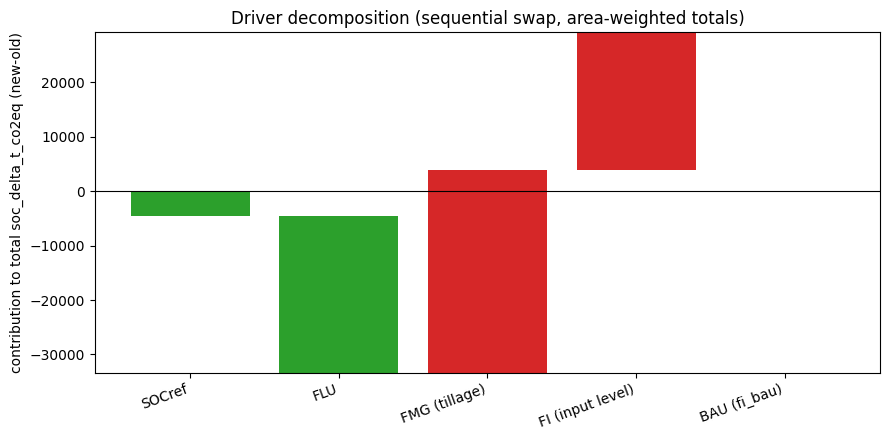

In [122]:
K = -3.67 / 20.0

def D(S, L, T, I, B):
    return K * S * L * (T * I - B)

d = both.dropna(subset=[
    "soc_ref_old", "flu_old", "ftill_old", "fi_old", "fi_bau_old",
    "soc_ref_new", "flu_new", "ftill_new", "fi_new", "fi_bau_new", "area_ha_new",
]).copy()
print(f"Rows usable for decomposition (all factors present old & new): {len(d)} / {len(both)}")
print("(dropped rows are mostly legacy Warm Temperate with fi = None)\n")

D0 = D(d.soc_ref_old, d.flu_old, d.ftill_old, d.fi_old, d.fi_bau_old)
D1 = D(d.soc_ref_new, d.flu_old, d.ftill_old, d.fi_old, d.fi_bau_old)
D2 = D(d.soc_ref_new, d.flu_new, d.ftill_old, d.fi_old, d.fi_bau_old)
D3 = D(d.soc_ref_new, d.flu_new, d.ftill_new, d.fi_old, d.fi_bau_old)
D4 = D(d.soc_ref_new, d.flu_new, d.ftill_new, d.fi_new, d.fi_bau_old)
D5 = D(d.soc_ref_new, d.flu_new, d.ftill_new, d.fi_new, d.fi_bau_new)

c = {
    "SOCref": D1 - D0,
    "FLU": D2 - D1,
    "FMG (tillage)": D3 - D2,
    "FI (input level)": D4 - D3,
    "BAU (fi_bau)": D5 - D4,
}

# Sanity checks: identity reproduces each script's output; swaps sum to the total change
res_id_old = (D0 - d.soc_delta_t_co2eq_ha_old).abs().max()
res_id_new = (D5 - d.soc_delta_t_co2eq_ha_new).abs().max()
total_ph = d.soc_delta_t_co2eq_ha_new - d.soc_delta_t_co2eq_ha_old
res_sum = (sum(c.values()) - total_ph).abs().max()
print(f"identity |D_old - script_old| max = {res_id_old:.2e}")
print(f"identity |D_new - script_new| max = {res_id_new:.2e}")
print(f"contributions sum to (new-old) resid max = {res_sum:.2e}\n")

contrib = pd.DataFrame({
    "mean_per_ha": {k: v.mean() for k, v in c.items()},
    "total_t_co2eq": {k: (v * d.area_ha_new).sum() for k, v in c.items()},
})
contrib.loc["— TOTAL —"] = contrib.sum()
display(contrib.round(3))

vals = [contrib.loc[k, "total_t_co2eq"] for k in c]
fig, ax = plt.subplots(figsize=(9, 4.5))
cum = np.concatenate([[0], np.cumsum(vals)[:-1]])
colors = ["tab:green" if v < 0 else "tab:red" for v in vals]  # negative = more sequestration
ax.bar(list(c.keys()), vals, bottom=cum, color=colors)
ax.axhline(0, color="k", lw=0.8)
ax.set_ylabel("contribution to total soc_delta_t_co2eq (new-old)")
ax.set_title("Driver decomposition (sequential swap, area-weighted totals)")
plt.xticks(rotation=20, ha="right"); plt.tight_layout(); plt.show()

## 4. Factor-by-factor detail

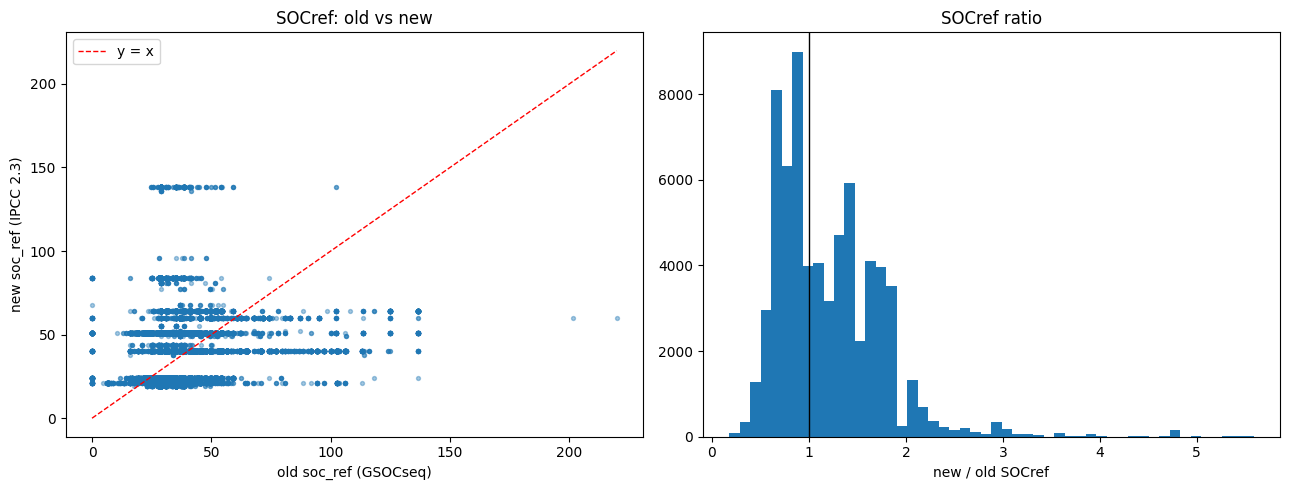

Mean SOCref — old: 35.39 | new: 40.3


,soc_ref_old,soc_ref_new
climate_class_new,,
Cool Temperate Moist,32.500000,91.6
Tropical Dry,31.700001,21.0
Tropical Moist,42.299999,40.1
Tropical Montane,33.900002,51.0
Tropical Wet,49.200001,59.7
Warm Temperate Dry,31.900000,26.8
Warm Temperate Moist,42.400002,72.5



Cross-check old soc_ref vs new soc_ref_gsocseq — max abs diff: 0.0000


In [128]:
# --- SOCref: IPCC Table 2.3 (new) vs GSOCseq (old) ---
s = both.dropna(subset=["soc_ref_old", "soc_ref_new"])
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].scatter(s["soc_ref_old"], s["soc_ref_new"], s=8, alpha=0.4)
lim = [0, max(s["soc_ref_old"].max(), s["soc_ref_new"].max())]
axes[0].plot(lim, lim, "r--", lw=1, label="y = x")
axes[0].set_xlabel("old soc_ref (GSOCseq)"); axes[0].set_ylabel("new soc_ref (IPCC 2.3)")
axes[0].set_title("SOCref: old vs new"); axes[0].legend()
ratio = (s["soc_ref_new"] / s["soc_ref_old"]).replace([np.inf, -np.inf], np.nan).dropna()
axes[1].hist(ratio, bins=50); axes[1].axvline(1, color="k", lw=1)
axes[1].set_xlabel("new / old SOCref"); axes[1].set_title("SOCref ratio")
plt.tight_layout(); plt.show()

print("Mean SOCref — old:", round(s["soc_ref_old"].mean(), 2),
      "| new:", round(s["soc_ref_new"].mean(), 2))
display(both.groupby("climate_class_new")[["soc_ref_old", "soc_ref_new"]].mean().round(1))

# Cross-check: old soc_ref should match the new script's soc_ref_gsocseq
ref_new = new_ns["soc_df_ref"][["farmer_id", "plot_id", "logbook_id", "practice_id",
                                "soc_ref_gsocseq", "soc_ref_ipcc"]].drop_duplicates()
chk = (old[["farmer_id", "plot_id", "logbook_id", "practice_id", "soc_ref"]].drop_duplicates()
       .merge(ref_new, on=["farmer_id", "plot_id", "logbook_id", "practice_id"], how="inner"))
gap = (chk["soc_ref"] - chk["soc_ref_gsocseq"]).abs()
print(f"\nCross-check old soc_ref vs new soc_ref_gsocseq — max abs diff: {gap.max():.4f}")

FLU by climate (mean):


,flu_old,flu_new
climate_class_new,,
Cool Temperate Moist,0.69,0.70
Tropical Dry,0.58,0.92
Tropical Moist,0.48,0.83
Tropical Montane,0.64,0.87
Tropical Wet,0.48,0.83
Warm Temperate Dry,0.80,0.76
Warm Temperate Moist,0.69,0.69


FMG / ftill by climate (mean):


,ftill_old,ftill_new
climate_class_new,,
Cool Temperate Moist,1.005,1.002
Tropical Dry,1.040,0.996
Tropical Moist,1.064,1.017
Tropical Montane,1.033,1.006
Tropical Wet,1.110,1.030
Warm Temperate Dry,1.004,0.998
Warm Temperate Moist,1.025,1.016


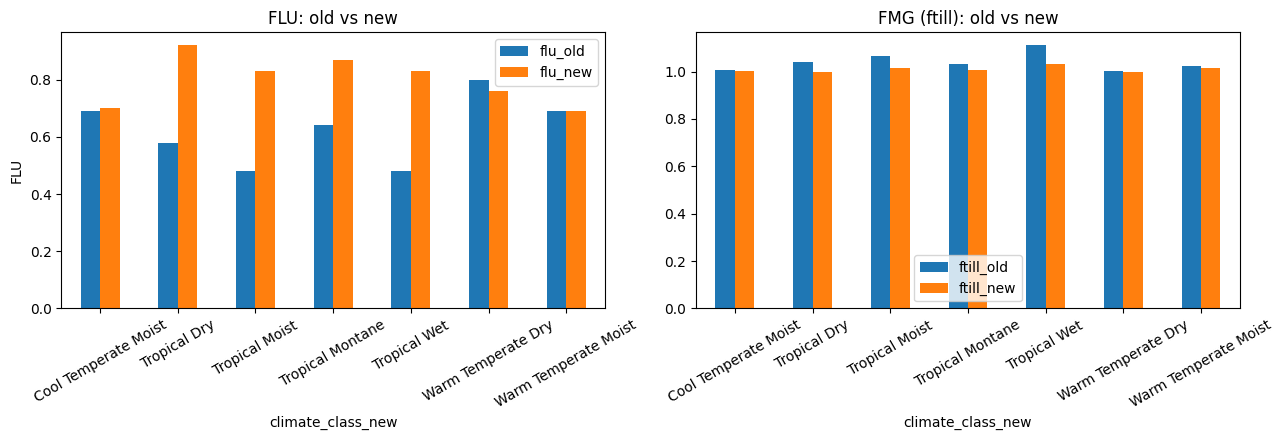

In [129]:
# --- FLU and FMG (tillage) by climate: 2006 -> 2019 shift ---
flu_tbl = both.groupby("climate_class_new")[["flu_old", "flu_new"]].mean().round(3)
ftill_tbl = both.groupby("climate_class_new")[["ftill_old", "ftill_new"]].mean().round(3)
print("FLU by climate (mean):"); display(flu_tbl)
print("FMG / ftill by climate (mean):"); display(ftill_tbl)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
flu_tbl.plot(kind="bar", ax=axes[0]); axes[0].set_title("FLU: old vs new"); axes[0].set_ylabel("FLU")
ftill_tbl.plot(kind="bar", ax=axes[1]); axes[1].set_title("FMG (ftill): old vs new")
for a in axes:
    a.tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.show()

In [135]:
## Check how many farms are assigned to each input category (FI level) in the new script's output vs. the old one
print("Farms by NEW FI level:")
display(both.groupby("fi_level_new").size())
print("Farms by OLD FI level:")
display(both.groupby("fi_level_old").size())

Farms by NEW FI level:


fi_level_new
High_no_manure        604
High_with_manure      362
Low                 46124
Medium              21604
dtype: int64

Farms by OLD FI level:


fi_level_old
High_no_manure      16370
High_with_manure      383
Low                 43725
Medium               8216
dtype: int64

In [131]:
# --- FI values by input level, and legacy None coverage gap ---
print("Mean fi by NEW level:")
display(both.groupby("fi_level_new")[["fi_new"]].mean().round(3))
print("Legacy fi == None (unmapped, e.g. Warm Temperate):", int(both["fi_old"].isna().sum()), "rows")
print("New fi == None:", int(both["fi_new"].isna().sum()), "rows")

wt = both[both["climate_class_new"].astype(str).str.startswith("Warm Temperate")]
print(f"\nWarm Temperate rows: {len(wt)} | legacy fi null: {int(wt['fi_old'].isna().sum())}")

Mean fi by NEW level:


,fi_new
fi_level_new,
High_no_manure,1.074
High_with_manure,1.398
Low,0.940
Medium,1.000


Legacy fi == None (unmapped, e.g. Warm Temperate): 30 rows
New fi == None: 22 rows

Warm Temperate rows: 22741 | legacy fi null: 0


## 5. Summary

Auto-computed highlights (see the printed numbers above for detail).

In [132]:
tot_old = both["soc_delta_t_co2eq_old"].sum()
tot_new = both["soc_delta_t_co2eq_new"].sum()
dominant = contrib.loc[list(c.keys()), "total_t_co2eq"]
dom_factor = dominant.abs().idxmax()

print("=== SUMMARY: old_soc.py -> 09_emissions_soc.py ===")
print(f"Total soc_delta_t_co2eq:  {tot_old:,.1f}  ->  {tot_new:,.1f}  "
      f"(change {tot_new - tot_old:,.1f} t CO2eq)")
print(f"Rows changing input level: {n_changed}/{len(both)} ({100*n_changed/len(both):.1f}%)")
print("Input-level counts (new): " + ", ".join(f"{k}={int(v)}" for k, v in lvl['new'].items()))
print(f"Largest single driver of the total change: {dom_factor} "
      f"({dominant[dom_factor]:,.1f} t CO2eq)")
print("Driver contributions to total change (t CO2eq):")
for k in c:
    print(f"   {k:18s}: {contrib.loc[k, 'total_t_co2eq']:,.1f}")

=== SUMMARY: old_soc.py -> 09_emissions_soc.py ===
Total soc_delta_t_co2eq:  -63,613.2  ->  -34,245.3  (change 29,367.9 t CO2eq)
Rows changing input level: 23139/68694 (33.7%)
Input-level counts (new): Low=46124, Medium=21604, High_no_manure=604, High_with_manure=362
Largest single driver of the total change: FMG (tillage) (37,266.6 t CO2eq)
Driver contributions to total change (t CO2eq):
   SOCref            : -4,542.6
   FLU               : -28,825.5
   FMG (tillage)     : 37,266.6
   FI (input level)  : 25,278.1
   BAU (fi_bau)      : 0.0


# Comparisons by ca_fao_dummy

In [ ]:
both.columns

Index(['farmer_id', 'plot_id', 'logbook_id', 'practice_id', 'year',
       'climate_class_corrected_old', 'soc_ref_old', 'flu_old', 'ftill_old',
       'fi_old', 'fi_bau_old', 'fi_level_old', 'ca_fao_dummy_old',
       'area_ha_old', 'soc_0_old', 'soc_1_old', 'soc_delta_old',
       'soc_delta_t_co2eq_old', 'soc_delta_t_co2eq_ha_old',
       'climate_class_corrected_new', 'soc_ref_new', 'flu_new', 'ftill_new',
       'fi_new', 'fi_bau_new', 'fi_level_new', 'ca_fao_dummy_new',
       'area_ha_new', 'soc_0_new', 'soc_1_new', 'soc_delta_new',
       'soc_delta_t_co2eq_new', 'soc_delta_t_co2eq_ha_new', '_merge'],
      dtype='object')

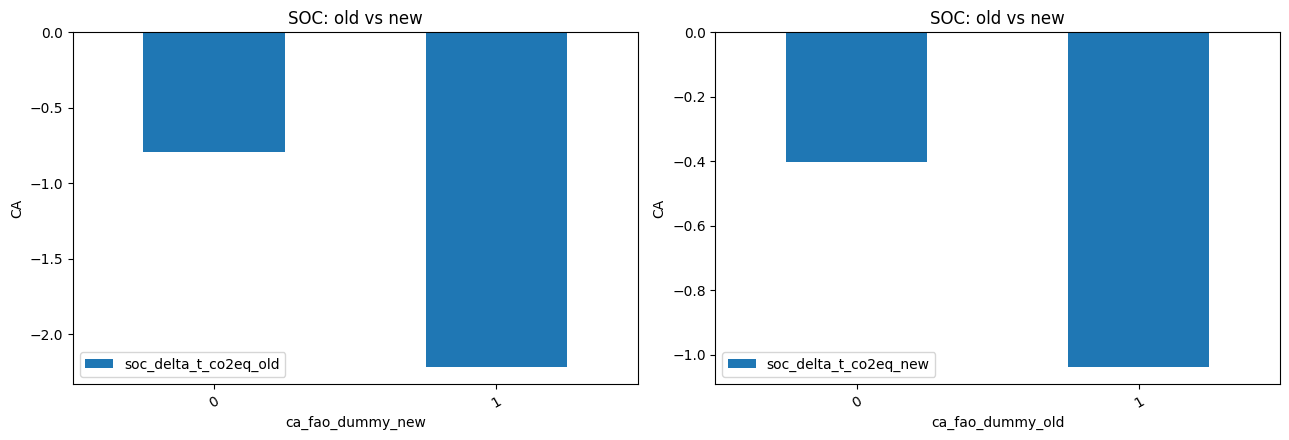

In [ ]:
# compare new and old results (SOC delta by ca_fao_dummy)
# create a bar plot with SOC_delta_t_co2eq by ca_fao_dummy for old and new, side by side

# --- FLU and FMG (tillage) by climate: 2006 -> 2019 shift ---
fao_tbl = both.groupby("ca_fao_dummy_new")[["soc_delta_t_co2eq_old"]].mean().round(3)
fao_tbl_old = both.groupby("ca_fao_dummy_old")[["soc_delta_t_co2eq_new"]].mean().round(3)


fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
fao_tbl.plot(kind="bar", ax=axes[0]); axes[0].set_title("SOC: old vs new"); axes[0].set_ylabel("CA")
fao_tbl_old.plot(kind="bar", ax=axes[1]); axes[1].set_title("SOC: old vs new"); axes[1].set_ylabel("CA")
for a in axes:
    a.tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.show()